# Exploration : météo de l'espace (tables propres)

Ce notebook lit les tables propres de la branche `clean-data` et en donne une première vue.

**Avant de l'exécuter** (une seule fois, dans le terminal de VS Code, depuis le dossier du projet) :

```powershell
git fetch origin clean-data
git worktree add data/clean clean-data
pip install -r requirements-dev.txt
```

Puis *Run All*. Pour récupérer les tables les plus récentes : `git -C data/clean fetch origin clean-data` puis `git -C data/clean reset --hard origin/clean-data` (pas de `pull` : la branche est republiée à chaque transformation).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from auroracast.data import load

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c2",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": "#e7e6e1", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

kp = load("kp_3h")
daily = load("solar_daily")
wind = load("solar_wind_hourly")
forecast = load("kp_forecast")
for name, df in [("kp_3h", kp), ("solar_daily", daily), ("solar_wind_hourly", wind), ("kp_forecast", forecast)]:
    print(f"{name:18} {len(df):>8} lignes")

kp_3h                277066 lignes
solar_daily           34632 lignes
solar_wind_hourly    147441 lignes
kp_forecast              25 lignes


## 1. Aperçu des tables

In [2]:
kp.tail(10)

,time,kp,ap,status,source
277056,2026-10-26 00:00:00+00:00,0.33,NaN,noaa_estimated,noaa
277057,2026-10-26 03:00:00+00:00,1.00,NaN,noaa_estimated,noaa
277058,2026-10-26 06:00:00+00:00,1.00,NaN,noaa_estimated,noaa
277059,2026-10-26 09:00:00+00:00,2.00,NaN,noaa_estimated,noaa
277060,2026-10-26 12:00:00+00:00,2.00,NaN,noaa_estimated,noaa
277061,2026-10-26 15:00:00+00:00,1.33,NaN,noaa_estimated,noaa
277062,2026-10-26 18:00:00+00:00,0.67,NaN,noaa_estimated,noaa
277063,2026-10-26 21:00:00+00:00,0.67,NaN,noaa_estimated,noaa
277064,2026-10-27 00:00:00+00:00,1.67,NaN,noaa_estimated,noaa
277065,2026-10-27 03:00:00+00:00,2.67,NaN,noaa_estimated,noaa


In [3]:
wind.describe().round(1)

,bt,by_gsm,bz_gsm,density,speed,bz_min,speed_max
count,146139.0,146113.0,146113.0,145505.0,146141.0,14.0,13.0
mean,5.7,-0.1,-0.1,6.2,421.3,-1.2,388.4
std,2.9,3.7,3.0,4.9,94.4,4.0,12.4
min,0.5,-34.1,-42.2,0.1,240.0,-7.6,373.2
25%,3.8,-2.5,-1.6,3.1,351.0,-3.9,378.7
50%,5.1,-0.2,-0.1,4.8,401.0,-1.0,387.9
75%,6.8,2.3,1.4,7.6,472.0,1.1,398.3
max,68.9,67.6,58.9,137.2,1121.0,5.4,415.1


## 2. Les tempêtes suivent le cycle solaire

Un *jour d'orage* est un jour où le Kp atteint au moins 5 (tempête G1 ou plus) sur au moins une tranche de 3 h.
Les deux graphiques partagent l'axe du temps. Les orages suivent le cycle solaire d'environ 11 ans, mais avec un décalage : les années les plus orageuses tombent souvent juste **après** le maximum de taches (phase descendante, quand les trous coronaux envoient des vents rapides répétés), ce qui limite la corrélation année par année.

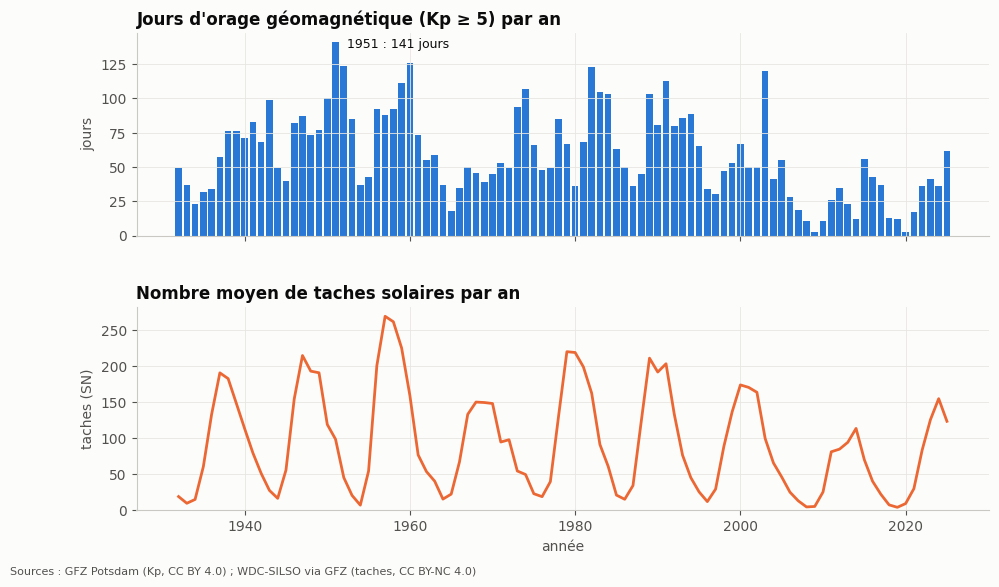

Corrélation annuelle jours d'orage / taches solaires : 0.45


In [4]:
day_max = kp.set_index("time")["kp"].resample("1D").max()
storm_days = (day_max >= 5).groupby(day_max.index.year).sum()
sunspots = daily.set_index("date")["sn"].groupby(daily["date"].dt.year.values).mean()
current = pd.Timestamp.now(tz="UTC").year
storm_days, sunspots = storm_days.loc[: current - 1], sunspots.loc[: current - 1]  # années complètes

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, gridspec_kw={"hspace": 0.35})
ax1.bar(storm_days.index, storm_days.values, color=BLUE, width=0.8)
ax1.set_title("Jours d'orage géomagnétique (Kp ≥ 5) par an")
ax1.set_ylabel("jours")
top = storm_days.idxmax()
ax1.annotate(f"{top} : {storm_days.max()} jours", (top, storm_days.max()), xytext=(8, -4),
             textcoords="offset points", fontsize=9, color=INK)
ax2.plot(sunspots.index, sunspots.values, color=ORANGE, linewidth=2)
ax2.set_title("Nombre moyen de taches solaires par an")
ax2.set_ylabel("taches (SN)")
ax2.set_xlabel("année")
for ax in (ax1, ax2):
    ax.set_ylim(bottom=0)
fig.text(0.01, 0.005, "Sources : GFZ Potsdam (Kp, CC BY 4.0) ; WDC-SILSO via GFZ (taches, CC BY-NC 4.0)",
         fontsize=8, color=MUTED)
plt.show()

print("Corrélation annuelle jours d'orage / taches solaires :",
      round(storm_days.corr(sunspots), 2))

## 3. Zoom sur la tempête de mai 2024

La plus forte tempête depuis 2003 : un Bz fortement négatif (champ orienté vers le sud) et un vent solaire rapide font monter le Kp jusqu'à 9.

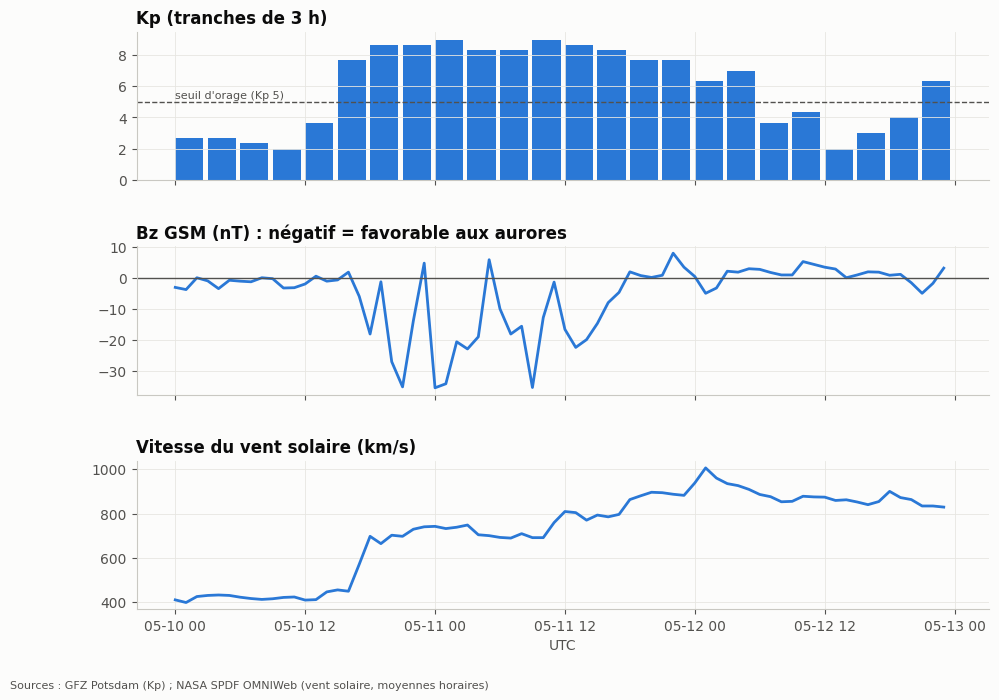

In [5]:
start, end = "2024-05-10", "2024-05-13"
k = kp[(kp["time"] >= start) & (kp["time"] < end)]
w = wind[(wind["time"] >= start) & (wind["time"] < end)]

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"hspace": 0.45})
axes[0].bar(k["time"], k["kp"], width=pd.Timedelta(hours=2.6), align="edge", color=BLUE)
axes[0].axhline(5, color=MUTED, linewidth=1, linestyle="--")
axes[0].text(k["time"].iloc[0], 5.2, "seuil d'orage (Kp 5)", fontsize=8, color=MUTED)
axes[0].set_title("Kp (tranches de 3 h)")
axes[0].set_ylim(0, 9.5)
axes[1].plot(w["time"], w["bz_gsm"], color=BLUE, linewidth=2)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].set_title("Bz GSM (nT) : négatif = favorable aux aurores")
axes[2].plot(w["time"], w["speed"], color=BLUE, linewidth=2)
axes[2].set_title("Vitesse du vent solaire (km/s)")
axes[2].set_xlabel("UTC")
fig.text(0.01, 0.005, "Sources : GFZ Potsdam (Kp) ; NASA SPDF OMNIWeb (vent solaire, moyennes horaires)",
         fontsize=8, color=MUTED)
plt.show()

## 4. Complétude du vent solaire

Part des heures où Bz est disponible, mois par mois (les points marquent les mois sous 90 %). Les creux correspondent à des pannes de satellites ; le mois en cours est presque vide tant qu'OMNIWeb n'a pas publié (2 à 4 semaines de retard).

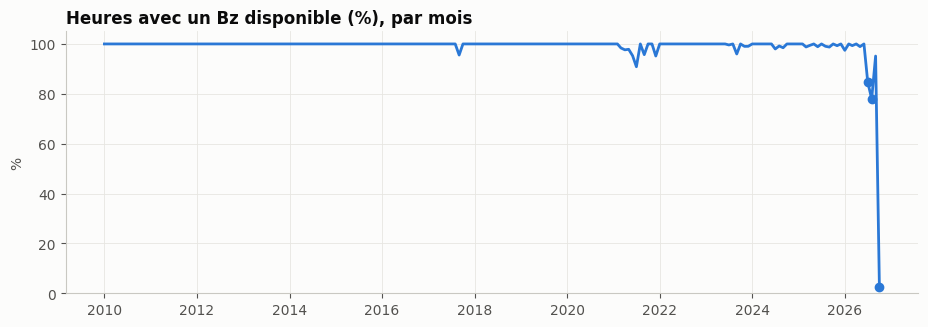

Mois sous 90 % : 07/2026 (85 %), 08/2026 (78 %), 10/2026 (3 %)


In [6]:
monthly = wind.set_index("time")["bz_gsm"].notna().resample("MS").mean() * 100
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.set_title("Heures avec un Bz disponible (%), par mois")
ax.set_ylim(0, 105)
ax.set_ylabel("%")
low = monthly[monthly < 90]
ax.scatter(low.index, low.values, s=36, color=BLUE, zorder=3)  # mois sous 90 %, listés ci-dessous
plt.show()
print("Mois sous 90 % :", ", ".join(f"{t:%m/%Y} ({v:.0f} %)" for t, v in low.items()) or "aucun")